# Simulated vs recorded electrode voltages

Compares the forward model against the 10 recorded electrode pairs. All computation comes from the shared modules:

- **`midline_methods.py`**: slice-spline midline per fish mask, head side chained through mask contacts.
- **`compute_electric_field.py`**: multipole sources, occupancy level set, system matrix with the skin as a thin sheet, Neumann solve.
- **`eod_assign.py`**: electrodes and recordings, the model's pair voltages, the comparison metric and the fish assignment.

Governing equation per angular frequency ω (Overleaf notes, p. 8–9):
$$\nabla\cdot(\gamma\,\nabla\hat\varphi) = -\hat s, \qquad \gamma = \sigma + i\omega\varepsilon .$$

**Comparison metric** (resistive case, ω = 0): the 10 pair voltages of the model and of the recording are each scaled so that
max |v| = 1, and the distance is the L2 norm of their difference. The recorded sample can sit in either phase of the EOD, so
the model vector is compared with both signs and the smaller distance is kept. The distance is 0 for identical patterns.

**Sections**
1. Data. 2. Midlines. 3. Geometry check. 4. Assignment of many recorded EODs (with the other fish as bodies, and in plain
water for comparison), with 3 good and 3 bad events in detail. The capacitive skin is left out for now: everything is
resistive (ω = 0).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from compute_electric_field import mask_to_grid
from eod_assign import (load_electrode_pairs, eod_sample_count, mask_frame, eods_with_masks, recorded_pair_traces,
                        midlines_with_continuity, candidate_field, assign_eod)

MASKS_NPY = 'data/video2024-02-20T21_16_26__223e__59997__masks_packed.mgz_masks_first_1000_frames.npy'
EOD_CSV = 'data/Data_4fish_2024-02-20T21_16_26.csv'
ELECTRODES_CSV = 'data/electrodes_signed_px_coord_2024-02-13.csv'

N = 200                # tank grid resolution (N x N)
n_poles = 100          # n_poles + 1 point currents along each midline, tail -> head
delta_h = 0.5          # skin thickness, in grid-cell units
FS = 20000.0           # electrode sampling rate (Hz)
N_EVENTS = 40          # recorded EODs assigned in section 4
SEED = 0

# normalized conductivities (sigma_water = 1), Migliaro/Caputi/Budelli (2005)
MAT = dict(
    sigma_water=1.0,      eps_water=0.0,
    sigma_interior=200.0, eps_interior=0.0,
    sigma_skin=0.05,      eps_skin=2.7e-6,
)

## 1. Data

`df_eod.Frame` is the 0-indexed video frame: the fish keypoints stored in each EOD row sit on `masks[:, Frame]`
(89% of keypoints inside the masks at fast-moving moments, vs 78% for `Frame - 1`).

In [2]:
masks = np.load(MASKS_NPY, mmap_mode='r')                 # (n_fish, n_frames, P, P) bool
n_fish, n_frames, P = masks.shape[0], masks.shape[1], masks.shape[2]
pairs = load_electrode_pairs(ELECTRODES_CSV, P)
pair_ids = [pid for pid, _, _ in pairs]

df_all = pd.read_csv(EOD_CSV)
n_samp = eod_sample_count(df_all)
df_eod = eods_with_masks(df_all, n_frames)

print(f"masks {masks.shape} | {len(pairs)} electrode pairs | {n_samp} samples per EOD @ {FS/1e3:.0f} kHz")
print(f"{len(df_eod)} recorded EODs in mask frames 0..{n_frames - 1}")

masks (4, 1001, 912, 912) | 10 electrode pairs | 25 samples per EOD @ 20 kHz
992 recorded EODs in mask frames 0..1000


## 2. Midlines with head continuity

The head is picked by the area rule outside contacts and chained through each contact episode. Checked against the CSV head and
tail keypoints, the midline head is right in 99.4% of fish-frames (all misses are fish 2 during contacts).

In [3]:
midlines, rules = midlines_with_continuity(masks, n_ctrl=n_poles + 1)
for f in range(n_fish):
    r = pd.Series([x for x in rules[f] if x is not None]).value_counts().to_dict()
    print(f"fish {f}: visible in {sum(m is not None for m in midlines[f])}/{n_frames} frames, head rule {r}")

fish 0: visible in 1001/1001 frames, head rule {'area': 1000, 'continuity': 1}
fish 1: visible in 1001/1001 frames, head rule {'area': 912, 'continuity': 89}
fish 2: visible in 1001/1001 frames, head rule {'area': 931, 'continuity': 70}
fish 3: visible in 1001/1001 frames, head rule {'area': 924, 'continuity': 77}


## 3. Geometry check

Fish masks with their midlines (tail sink as a blue square, head as a red dot) and the electrode pairs (`+` red, `-` blue).

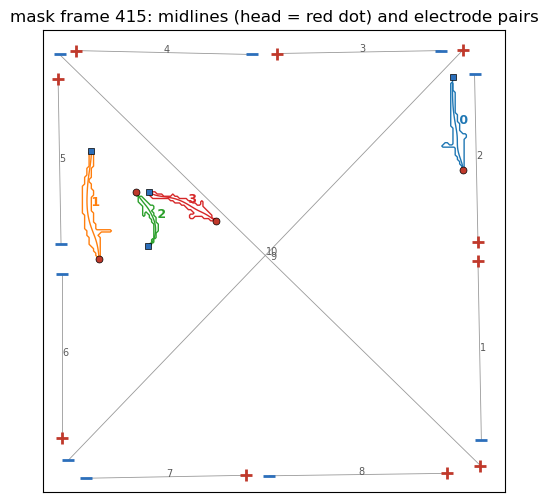

In [4]:
g = np.linspace(0, 1, N)
fish_colors = plt.cm.tab10.colors

def draw_scene(ax, fr, emitter=None):
    for f in range(n_fish):
        m = np.asarray(masks[f, fr])
        if not m.any(): continue
        ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5], colors=[fish_colors[f]],
                   linewidths=2.0 if f == emitter else 1.0, linestyles='--' if f == emitter else '-')
        mid = midlines[f][fr]
        if mid is not None:
            ax.plot(mid[:, 0], mid[:, 1], '-', color=fish_colors[f], lw=1)
            ax.plot(*mid[-1], 'o', color='#C0392B', ms=5, mec='k', mew=0.5)
            ax.plot(*mid[0], 's', color='#2C6FBB', ms=5, mec='k', mew=0.5)
            ax.text(*mid[len(mid) // 2], f' {f}', color=fish_colors[f], fontsize=9, weight='bold')
    for pid, pp, pm in pairs:
        ax.plot([pp[0], pm[0]], [pp[1], pm[1]], color='0.6', lw=0.6, zorder=0)
        ax.plot(*pp, '+', color='#C0392B', ms=8, mew=2); ax.plot(*pm, '_', color='#2C6FBB', ms=8, mew=2)
        ax.text(*(0.5 * (pp + pm)), str(pid), fontsize=7, color='0.35')
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(figsize=(6, 6))
ex_frame = mask_frame(df_eod.iloc[len(df_eod) // 2])
draw_scene(ax, ex_frame)
ax.set_title(f"mask frame {ex_frame}: midlines (head = red dot) and electrode pairs")
plt.show()

## 4. Assigning recorded EODs

`assign_eod` takes the recorded pair voltages at the sample where |V| peaks, solves every visible fish's resistive unit-current
field, and assigns the EOD to the fish with the smallest distance. The *margin* (second-best minus best distance) says how clearly
the winner stands out. Each EOD is assigned twice: with the other fish as skin + interior bodies, and in plain water.

In [5]:
rng = np.random.default_rng(SEED)
ev_rows = np.sort(rng.choice(df_eod.index.to_numpy(), size=min(N_EVENTS, len(df_eod)), replace=False))

out = []
for n, r in enumerate(ev_rows):
    row = df_eod.loc[r]; fr = mask_frame(row)
    fm = np.asarray(masks[:, fr]); fmid = [midlines[f][fr] for f in range(n_fish)]
    for bodies in (True, False):
        a = assign_eod(row, fm, fmid, pairs, N, delta_h, MAT, n_samp, bodies=bodies)
        d = sorted(a['distances'].values())
        out.append(dict(row=r, frame=fr, bodies=bodies, margin=d[1] - d[0] if len(d) > 1 else np.nan, **a))
    if (n + 1) % 10 == 0: print(f"{n + 1}/{len(ev_rows)} events")

res = pd.DataFrame(out)
a_with, a_water = res[res.bodies].set_index('row'), res[~res.bodies].set_index('row')
for name, a in (('with bodies', a_with), ('plain water', a_water)):
    print(f"{name:12s}: distance median {a.distance.median():.2f} (10%: {a.distance.quantile(0.1):.2f}, "
          f"90%: {a.distance.quantile(0.9):.2f}) | margin median {a.margin.median():.2f} | "
          f"winners per fish {a.fish.value_counts().sort_index().to_dict()}")
print(f"same winner with and without bodies in {(a_with.fish == a_water.fish).mean():.0%} of events")

10/40 events


20/40 events


30/40 events


40/40 events
with bodies : distance median 1.38 (10%: 0.58, 90%: 1.55) | margin median 0.19 | winners per fish {0: 4, 1: 9, 2: 14, 3: 13}
plain water : distance median 1.38 (10%: 0.63, 90%: 1.59) | margin median 0.16 | winners per fish {0: 4, 1: 10, 2: 12, 3: 14}
same winner with and without bodies in 80% of events


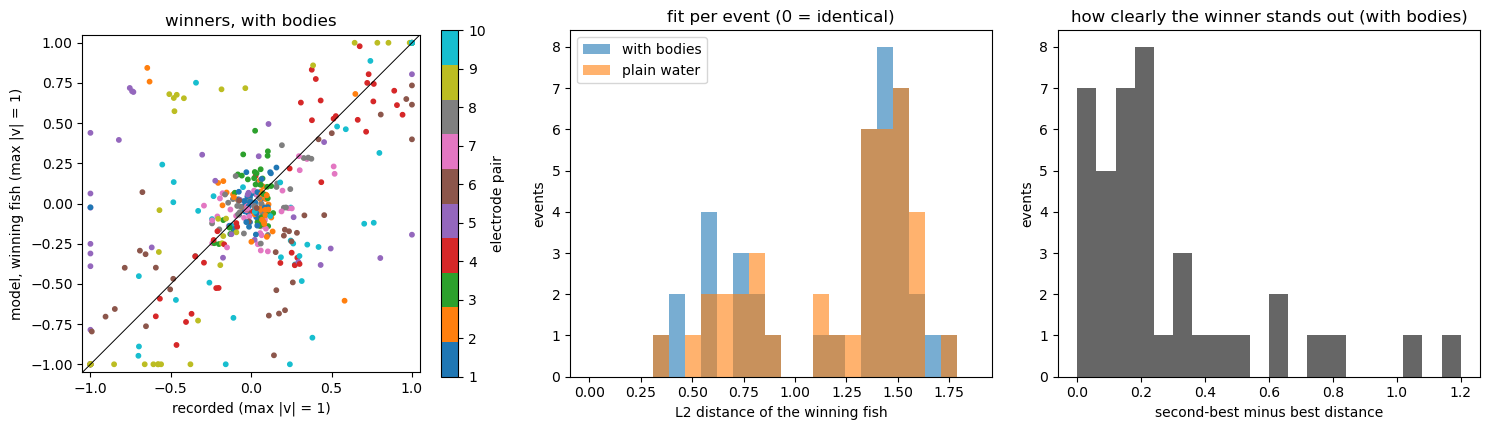

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))

sim = np.concatenate([a.v_sim[a.fish] for _, a in a_with.iterrows()])
rec = np.concatenate(a_with.v_rec.to_list())
sc = ax[0].scatter(rec, sim, c=np.tile(pair_ids, len(a_with)), cmap='tab10', s=10)
ax[0].plot([-1.05, 1.05], [-1.05, 1.05], 'k-', lw=0.7)
ax[0].set(xlabel='recorded (max |v| = 1)', ylabel='model, winning fish (max |v| = 1)', aspect='equal',
          xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), title='winners, with bodies')
fig.colorbar(sc, ax=ax[0], label='electrode pair')

bins = np.linspace(0, res.distance.max() * 1.05, 25)
ax[1].hist(a_with.distance, bins, alpha=0.6, label='with bodies')
ax[1].hist(a_water.distance, bins, alpha=0.6, label='plain water')
ax[1].set(xlabel='L2 distance of the winning fish', ylabel='events', title='fit per event (0 = identical)')
ax[1].legend()

ax[2].hist(a_with.margin, 20, color='0.4')
ax[2].set(xlabel='second-best minus best distance', ylabel='events', title='how clearly the winner stands out (with bodies)')
plt.tight_layout(); plt.show()

### Good and bad events

The 3 events with the smallest winning distance and the 3 with the largest (with bodies). Left: the normalized recorded pair
voltages (black) next to every visible fish's resistive model pattern (normalized and sign-aligned), with each fish's distance.
Right: the winner's potential with all fish and the electrodes on top.

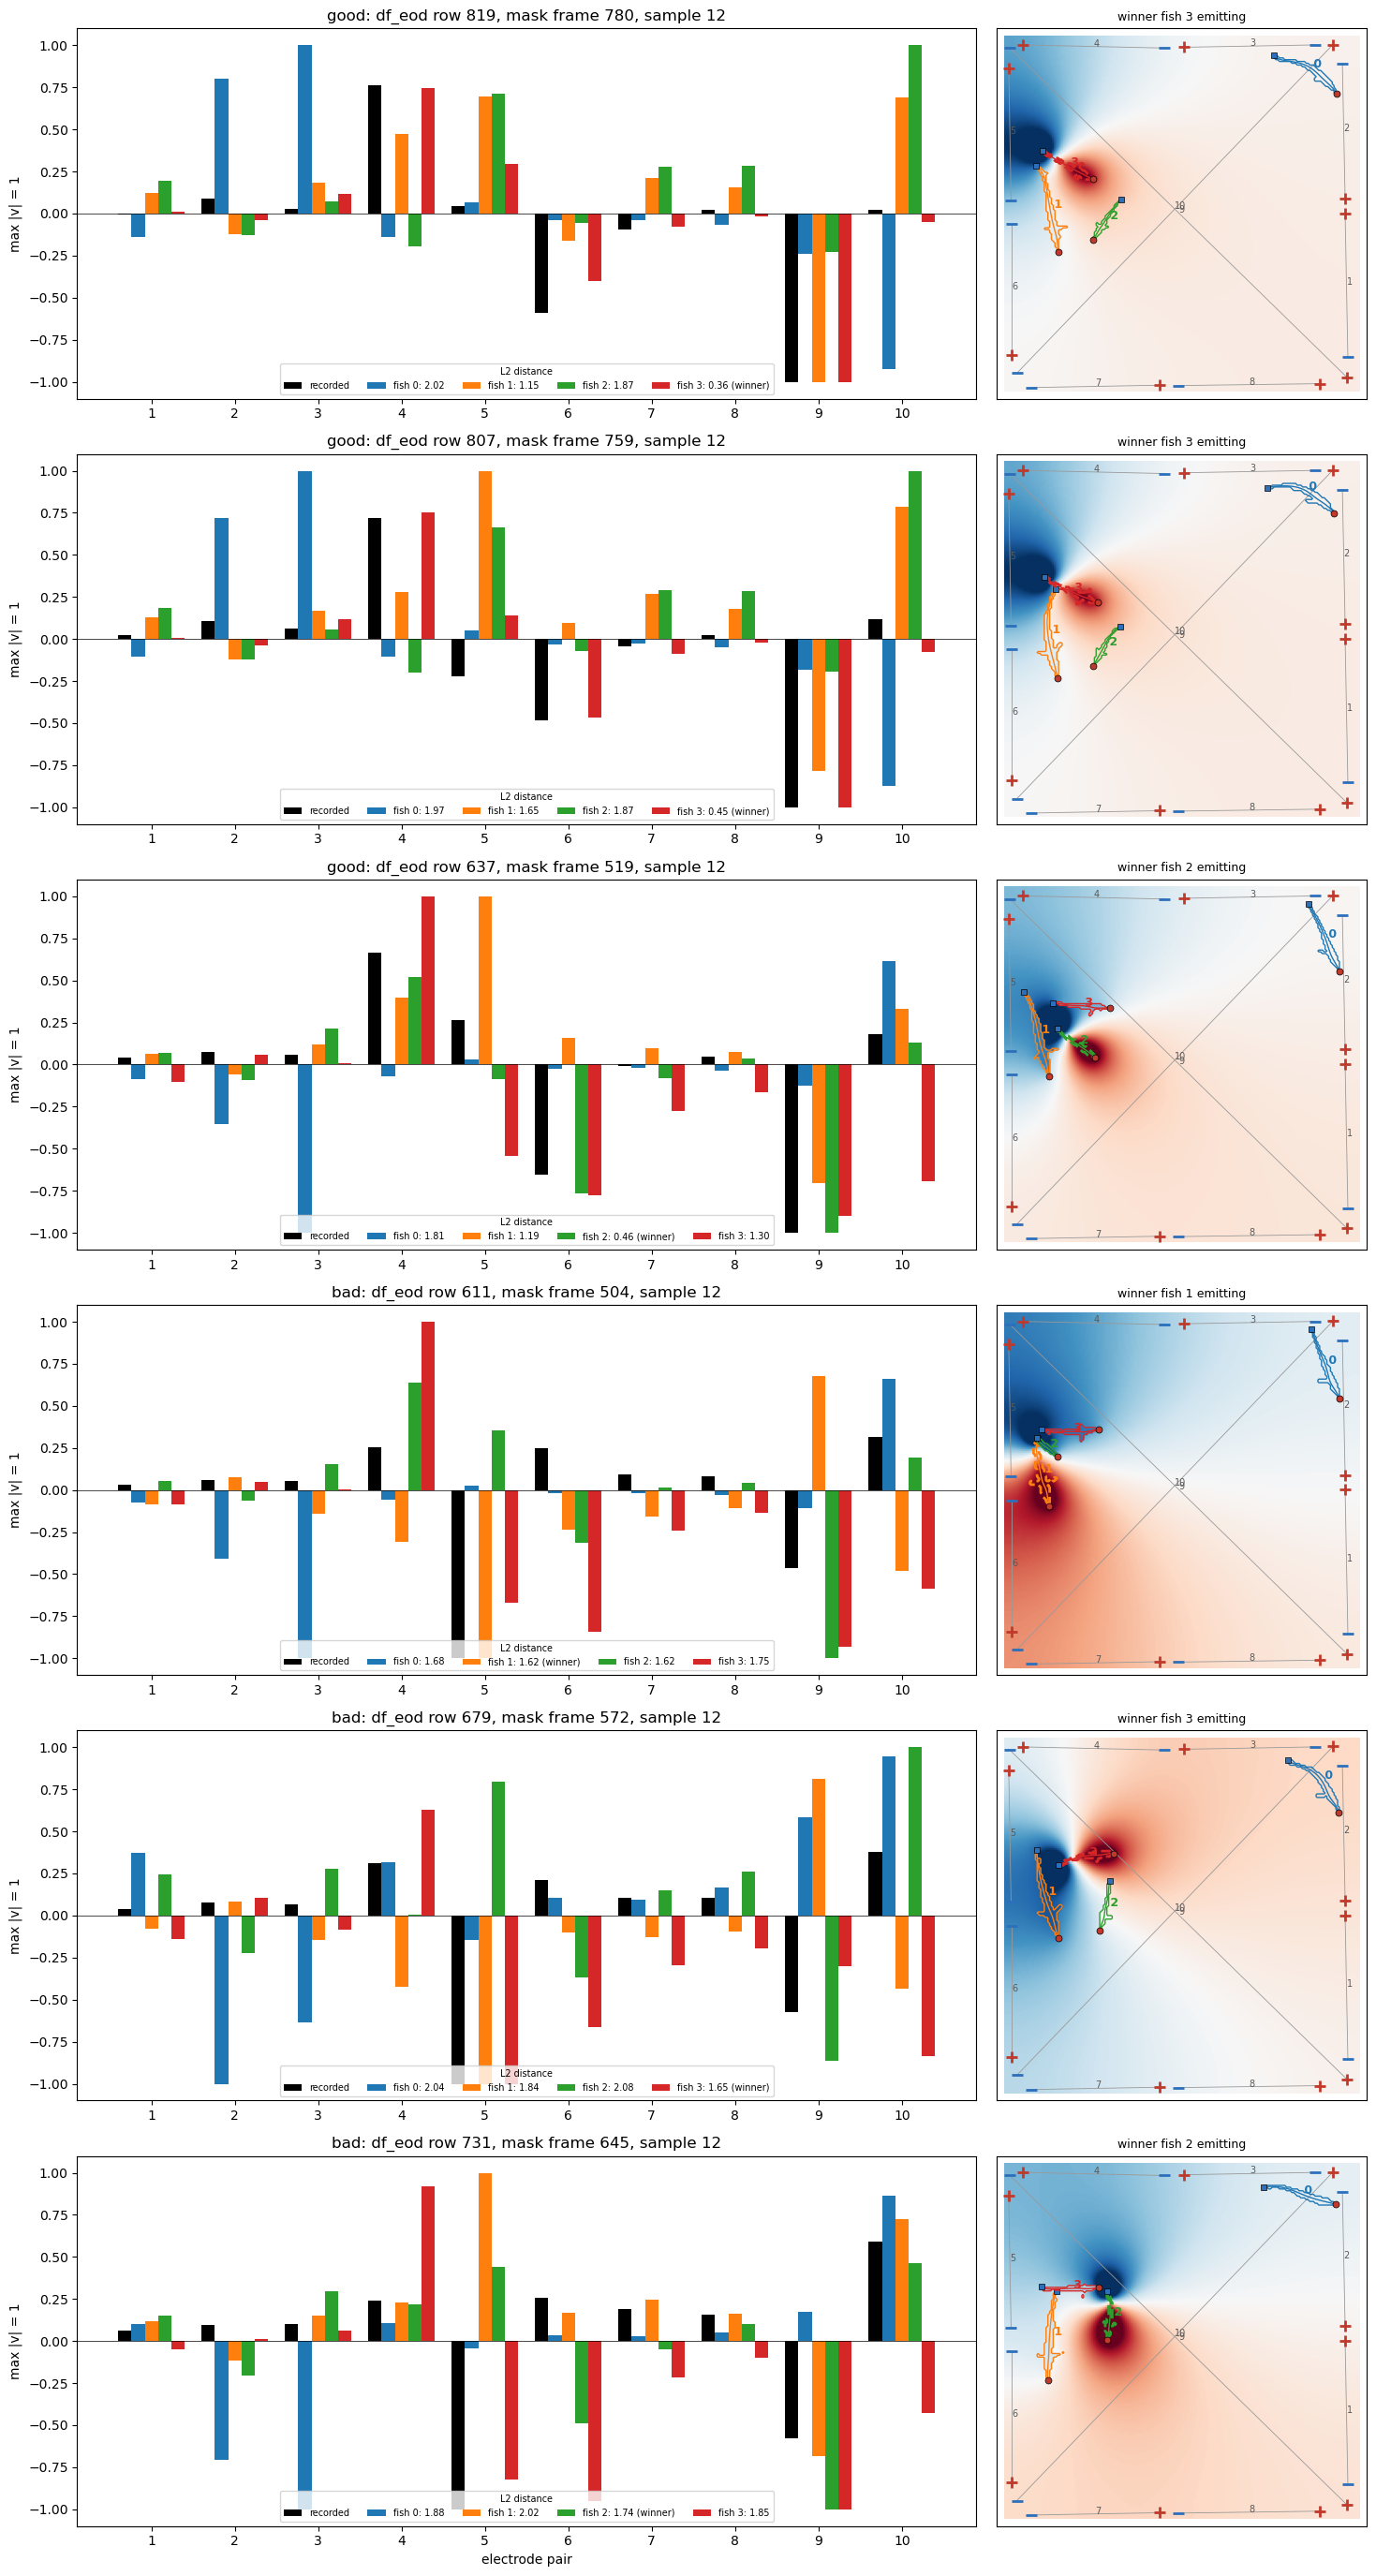

In [7]:
def plot_event(ax_bar, ax_map, r, label):
    a = a_with.loc[r]; fr, win = int(a.frame), int(a.fish)
    dists, vs = a.distances, a.v_sim
    x = np.arange(len(pair_ids)); w = 0.8 / (len(vs) + 1)
    ax_bar.bar(x - 0.4 + w / 2, a.v_rec, w, color='k', label='recorded')
    for k, f in enumerate(sorted(vs)):
        ax_bar.bar(x - 0.4 + w * (k + 1.5), vs[f], w, color=fish_colors[f],
                   label=f"fish {f}: {dists[f]:.2f}" + (" (winner)" if f == win else ""))
    ax_bar.axhline(0, color='k', lw=0.5)
    ax_bar.set(xticks=x, xticklabels=pair_ids, ylim=(-1.1, 1.1), ylabel='max |v| = 1',
               title=f'{label}: df_eod row {r}, mask frame {fr}, sample {a.t_star}')
    ax_bar.legend(fontsize=7, ncol=5, loc='lower center', title='L2 distance', title_fontsize=7)

    phi = candidate_field(np.asarray(masks[:, fr]), win, midlines[win][fr], N, delta_h, MAT).real
    v = np.percentile(np.abs(phi), 99)
    ax_map.imshow(phi.T, origin='lower', extent=[0, 1, 0, 1], cmap='RdBu_r', vmin=-v, vmax=v)
    draw_scene(ax_map, fr, emitter=win)
    ax_map.set_title(f'winner fish {win} emitting', fontsize=9)

order = a_with.distance.sort_values()
picked = [(r, 'good') for r in order.index[:3]] + [(r, 'bad') for r in order.index[-3:]]
fig, axes = plt.subplots(len(picked), 2, figsize=(15, 4.6 * len(picked)), gridspec_kw=dict(width_ratios=[2.2, 1]))
for (r, label), (ax_bar, ax_map) in zip(picked, axes):
    plot_event(ax_bar, ax_map, r, label)
axes[-1, 0].set_xlabel('electrode pair')
plt.tight_layout(); plt.show()